# Section 4 results

Figures 4.1–4.7 from the Practical 1 report. The saved chart outputs are the
images embedded in the PDF. Run the plotting cells to regenerate the charts
from `results/timings.csv` using the recorded sessions below.

Line plots show the median and interquartile range across five replicates.
Build bars show medians, and the memory panel shows added index memory.

| Experiment | Machine | Code version | Session |
| --- | --- | --- | --- |
| E1 | `oscar-omen` | `584f39d` | `52cd11d6d84d` |
| E2 | `oscar-omen` | `584f39d` | `e7f9f25e01b5` |
| E3 | `oscar-omen` | `584f39d` | `56a7e705caf6` |
| E4 | `ike-mba` | `c2b371c` | `a9a62ee605d5` |
| E5 | `oscar-omen` | `584f39d` | `f3a0df8f5704` |
| E6 | `oscar-omen` | `584f39d` | `7e671042e940` |
| E7 | `zaid-mbp` | `b8f1dc3` | `011c03dc3a2f` |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

csv_path = Path("results/timings.csv")
if not csv_path.is_file():
    csv_path = Path("../results/timings.csv")
timings = pd.read_csv(csv_path)
timings["total_ms"] = timings["total_ns"] / 1_000_000
timings["us_per_op"] = timings["total_ns"] / timings["n_ops"] / 1_000

INDEX_COLORS = {
    "unsorted_list": "#2a78d6",
    "sorted_list": "#eb6834",
    "hash_table": "#1baf7a",
    "avl_tree": "#eda100",
    "bplus_tree": "#e87ba4",
    "ref_dict": "#008300",
    "ref_bisect": "#6250d6",
}
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.axisbelow": True,
    "axes.grid": True,
    "grid.color": "#e3e5e8",
    "grid.linewidth": 0.6,
    "legend.framealpha": 0.92,
})


def select_run(experiment, machine, version, session):
    rows = timings.loc[
        (timings["experiment"] == experiment)
        & (timings["machine_id"] == machine)
        & (timings["code_version"] == version)
        & (timings["session_id"] == session)
    ].copy()
    if rows.empty:
        raise ValueError(f"No rows for {experiment}, {machine}, {version}, {session}")
    return rows


def summarize(rows, by, metric):
    values = rows.groupby(by)[metric]
    return pd.DataFrame({
        "median": values.median(),
        "q1": values.quantile(0.25),
        "q3": values.quantile(0.75),
    })


def plot_curve(ax, summary, color, label=None, linestyle="-"):
    ax.plot(
        summary.index, summary["median"], color=color, label=label,
        linestyle=linestyle, marker="o", markersize=4, linewidth=1.4,
    )
    ax.fill_between(summary.index, summary["q1"], summary["q3"], color=color, alpha=0.16)


def plot_indexes(ax, rows, by, metric):
    for name, color in INDEX_COLORS.items():
        selected = rows.loc[rows["index_type"] == name]
        style = "--" if name.startswith("ref_") else "-"
        plot_curve(ax, summarize(selected, by, metric), color, name, style)


def plot_build_bars(table, colors, title, legend_title):
    fig, ax = plt.subplots(figsize=(9.4, 4.25), layout="constrained")
    table.plot.bar(ax=ax, logy=True, color=colors, width=0.84)
    ax.set(title=title, xlabel="", ylabel="build time, ms (median)")
    ax.xaxis.grid(False)
    ax.set_xticks(ax.get_xticks(), table.index, rotation=22, ha="right")
    ax.legend(title=legend_title, loc="upper left", fontsize=8)
    plt.show()

## 4.1 E1 build and memory

Build time by input size and added memory at 114,000 `track_id` pairs.

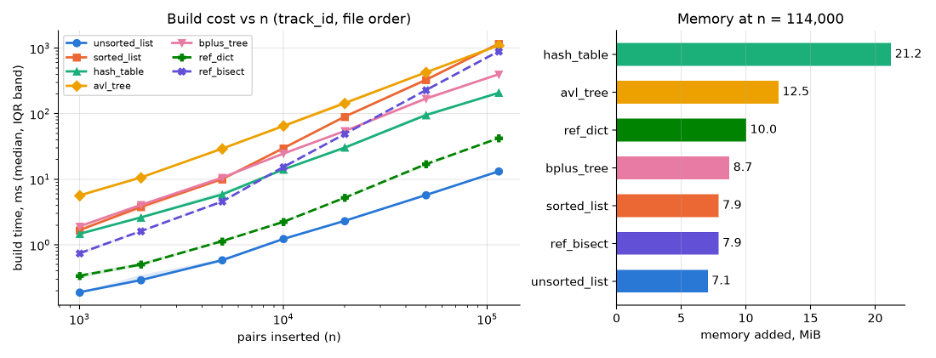

In [2]:
# 4.1 E1 build and memory
e1 = select_run("E1_build_memory", "oscar-omen", "584f39d", "52cd11d6d84d")
fig, (build_ax, memory_ax) = plt.subplots(
    1, 2, figsize=(12, 4.6), width_ratios=[1.7, 1], layout="constrained"
)
plot_indexes(build_ax, e1, "n_keys", "total_ms")
build_ax.set(
    title="Build cost vs n (track_id, file order)", xlabel="pairs inserted (n)",
    ylabel="total build time, ms (median, IQR band)", xscale="log", yscale="log",
)
build_ax.legend(loc="upper left", ncols=2, fontsize=8)

full_e1 = e1.loc[e1["n_keys"] == 114_000]
memory = (full_e1.groupby("index_type")["memory_bytes"].median() / 2**20).sort_values(
    ascending=False
)
bars = memory_ax.barh(memory.index, memory, color=[INDEX_COLORS[name] for name in memory.index])
memory_ax.bar_label(bars, fmt="%.1f", padding=3)
memory_ax.invert_yaxis()
memory_ax.yaxis.grid(False)
memory_ax.set(title="Memory at n = 114,000", xlabel="memory added, MiB", xlim=(0, 24))
plt.show()

In [3]:
# Fitted slopes for the E1 build-time comparison in the report.
vivian_e1 = select_run("E1_build_memory", "vivian-mbp", "3c5068c", "639a2f3e55f8")
slope_rows = []
for run in (e1, vivian_e1):
    for name, rows in run.groupby("index_type"):
        medians = rows.groupby("n_keys")["total_ms"].median()
        slope = np.polyfit(np.log(medians.index), np.log(medians), deg=1)[0]
        slope_rows.append((name, rows["machine_id"].iloc[0], slope))
slopes = pd.DataFrame(slope_rows, columns=["index", "machine", "slope"])
display(slopes.pivot(index="index", columns="machine", values="slope").round(2))

machine,oscar-omen,vivian-mbp
index,,
avl_tree,1.13,1.11
bplus_tree,1.14,1.11
hash_table,1.08,1.02
ref_bisect,1.52,1.66
ref_dict,1.05,1.03
sorted_list,1.40,1.49
unsorted_list,0.91,0.97


## 4.2 E2 point lookups

Point hits and misses on `track_id` across seven index sizes, using the fixed code.

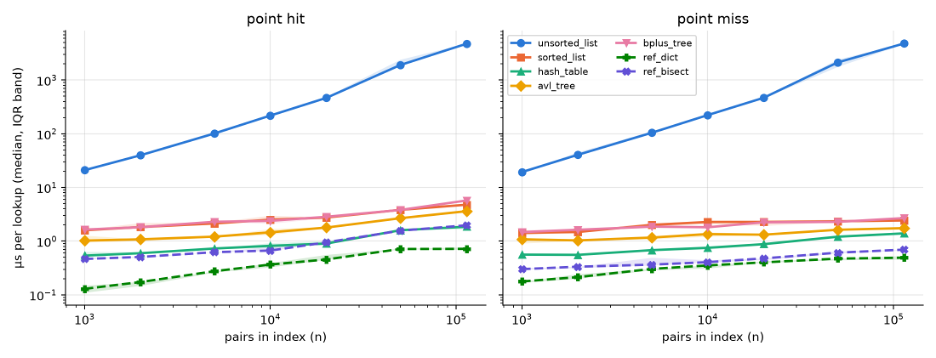

In [4]:
# 4.2 E2 point lookups
e2 = select_run("E2_point_lookups", "oscar-omen", "584f39d", "e7f9f25e01b5")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True, layout="constrained")
for operation, ax in zip(("point_hit", "point_miss"), axes):
    rows = e2.loc[e2["operation"] == operation]
    plot_indexes(ax, rows, "n_keys", "us_per_op")
    ax.set(title=operation.replace("_", " "), xlabel="pairs in index (n)", xscale="log", yscale="log")
axes[0].set_ylabel("µs per lookup (median, IQR band)")
axes[1].legend(loc="upper left", ncols=2, fontsize=8)
plt.show()

## 4.3 E3 range

Tempo range query time across six fractions of distinct tempo keys.

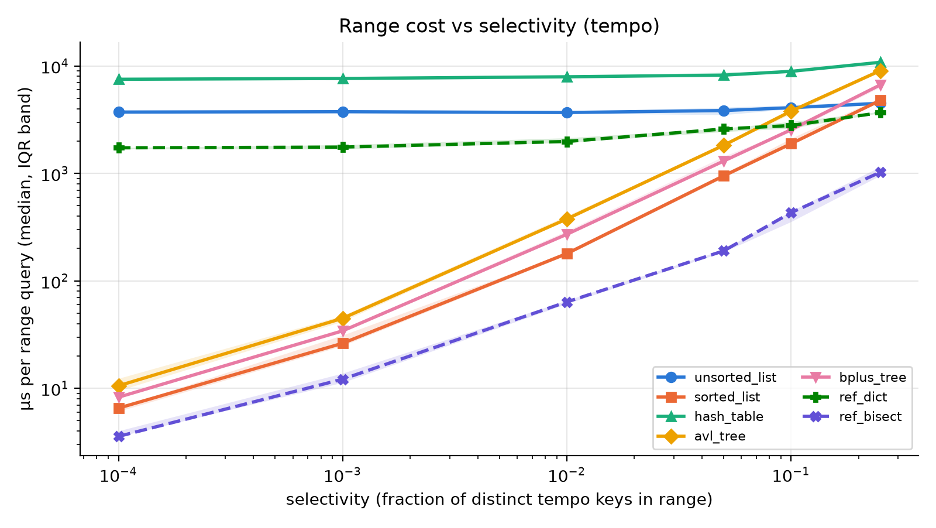

In [5]:
# 4.3 E3 range
e3 = select_run("E3_range_tempo", "oscar-omen", "584f39d", "56a7e705caf6")
fig, ax = plt.subplots(figsize=(9.4, 5.3), layout="constrained")
plot_indexes(ax, e3, "operation_param", "us_per_op")
ax.set(
    title="Range cost vs selectivity (tempo)",
    xlabel="selectivity (fraction of distinct tempo keys in range)",
    ylabel="µs per range query (median, IQR band)", xscale="log", yscale="log",
)
ax.legend(loc="lower right", ncols=2, fontsize=8)
plt.show()

## 4.4 E4 prefix

Track-title prefix query time for prefixes of one to five characters.

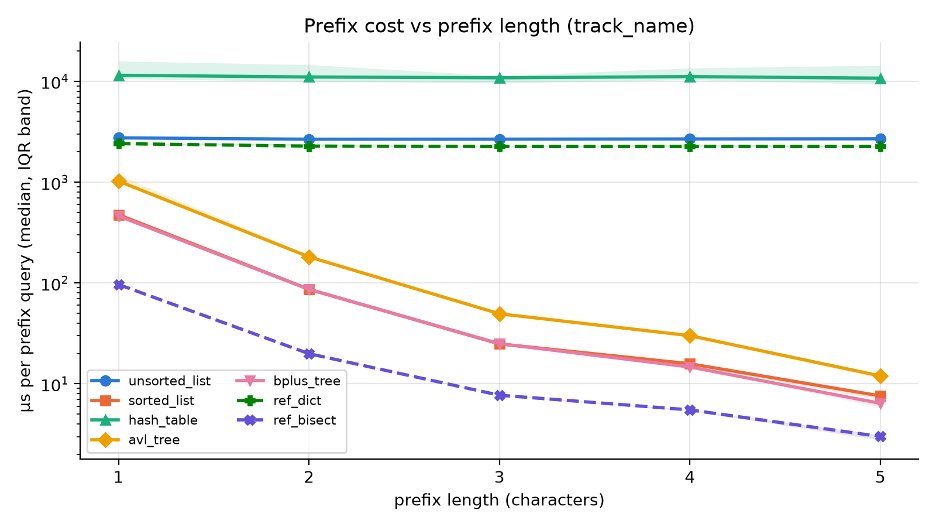

In [6]:
# 4.4 E4 prefix
e4 = select_run("E4_prefix_track_name", "ike-mba", "c2b371c", "a9a62ee605d5")
fig, ax = plt.subplots(figsize=(9.4, 5.3), layout="constrained")
plot_indexes(ax, e4, "operation_param", "us_per_op")
ax.set(
    title="Prefix cost vs prefix length (track_name)", xlabel="prefix length (characters)",
    ylabel="µs per prefix query (median, IQR band)", yscale="log", xticks=range(1, 6),
)
ax.legend(loc="lower left", ncols=2, fontsize=8)
plt.show()

In [7]:
# Table 4.1. Median µs per prefix query, ike-mba.
prefix_table = e4.groupby(["index_type", "operation_param"])["us_per_op"].median().unstack()
prefix_table.columns = [f"Length {int(length)}" for length in prefix_table.columns]
reported_indexes = ["bplus_tree", "sorted_list", "avl_tree", "unsorted_list", "hash_table", "ref_bisect"]
display(prefix_table.loc[reported_indexes].round(2))

,Length 1,Length 2,Length 3,Length 4,Length 5
index_type,,,,,
bplus_tree,461.90,86.52,25.03,14.69,6.41
sorted_list,476.06,86.59,24.87,15.82,7.59
avl_tree,1024.18,181.59,49.50,30.04,11.98
unsorted_list,2749.28,2667.09,2669.76,2681.87,2692.73
hash_table,11481.14,11042.01,10838.89,11140.54,10742.41
ref_bisect,96.60,19.91,7.71,5.51,3.00


## 4.5 E5 insert order

Median total build time for 100,000 synthetic keys in four arrival orders.

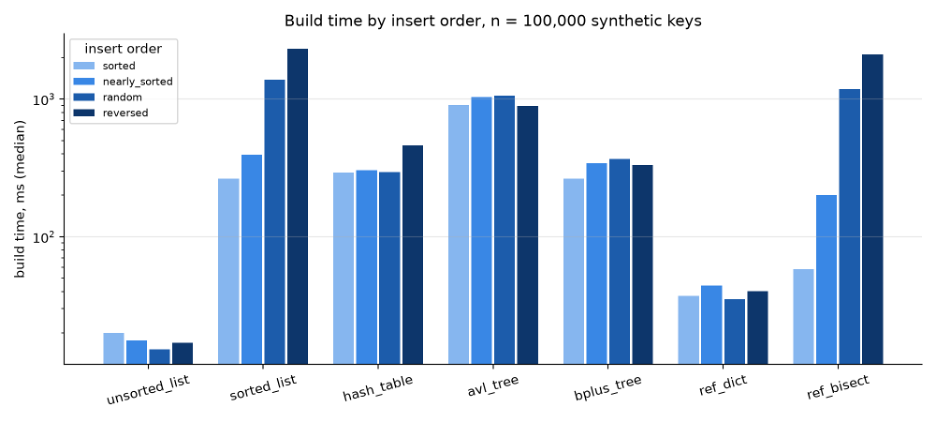

In [8]:
# 4.5 E5 insert order
e5 = select_run("E5_insert_order", "oscar-omen", "584f39d", "f3a0df8f5704")
builds = e5.loc[(e5["operation"] == "build") & (e5["n_keys"] == 100_000)]
order_times = builds.groupby(["index_type", "insert_order"])["total_ms"].median().unstack()
order_times = order_times.reindex(
    index=list(INDEX_COLORS), columns=["sorted", "nearly_sorted", "random", "reversed"]
)
plot_build_bars(
    order_times, ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"],
    "Build time by insert order, n = 100,000 synthetic keys", "insert order",
)

## 4.6 E6 B+ tree order

Build cost per insert, point hits, and 1% tempo ranges at 114,000 pairs.

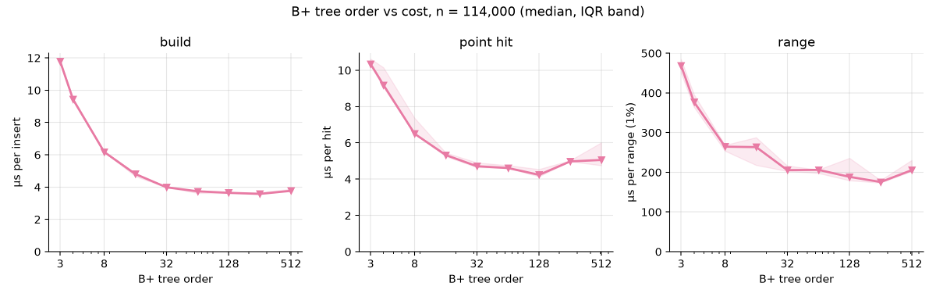

In [9]:
# 4.6 E6 B+ tree order
e6 = select_run("E6_bplus_order", "oscar-omen", "584f39d", "7e671042e940")
e6_full = e6.loc[e6["n_keys"] == 114_000].copy()
e6_full["order"] = e6_full["index_param"].str.extract(r"order=(\d+)", expand=False).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.85), layout="constrained")
panels = [("build", "µs per insert"), ("point_hit", "µs per lookup"), ("range", "µs per range (1%)")]
order_ticks = [3, 8, 32, 128, 512]
for ax, (operation, ylabel) in zip(axes, panels):
    rows = e6_full.loc[e6_full["operation"] == operation]
    plot_curve(ax, summarize(rows, "order", "us_per_op"), INDEX_COLORS["bplus_tree"])
    ax.set_xscale("log", base=2)
    ax.set_xticks(order_ticks, [str(order) for order in order_ticks])
    ax.set(title=operation.replace("_", " "), xlabel="B+ tree order", ylabel=ylabel, ylim=(0, None))
fig.suptitle("B+ tree order vs cost, n = 114,000 (median, IQR band)")
plt.show()

In [10]:
# Table 4.2. Median µs per operation, oscar-omen.
by_order = e6_full.groupby(["operation", "order"])["us_per_op"].median().unstack("order")
reported_ops = ["build", "point_hit", "range"]
order_table = pd.DataFrame({
    "Best order": by_order.idxmin(axis=1),
    "Best (µs)": by_order.min(axis=1),
    "Order 3 (µs)": by_order[3],
    "Order 32 (µs)": by_order[32],
})
display(order_table.loc[reported_ops].round(3))

,Best order,Best (µs),Order 3 (µs),Order 32 (µs)
operation,,,,
build,256,3.577,11.780,3.985
point_hit,128,4.235,10.344,4.709
range,256,175.493,468.936,205.395


## 4.7 E7 duplicate keys

Median total build time for 114,000 pairs, grouped by key column.

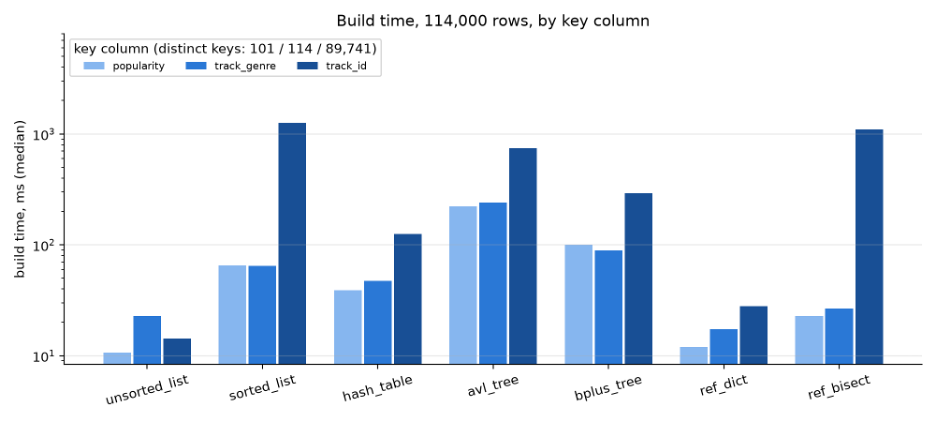

In [11]:
# 4.7 E7 duplicate keys
e7 = select_run("E7_duplicate_keys", "zaid-mbp", "b8f1dc3", "011c03dc3a2f")
builds = e7.loc[(e7["operation"] == "build") & (e7["n_keys"] == 114_000)]
column_times = builds.groupby(["index_type", "key_column"])["total_ms"].median().unstack()
column_times = column_times.reindex(
    index=list(INDEX_COLORS), columns=["popularity", "track_genre", "track_id"]
)
plot_build_bars(
    column_times, ["#86b6ef", "#2a78d6", "#184f95"],
    "Build time, 114,000 rows, by key column", "key column (distinct keys: 101 / 114 / 89,741)",
)